# Member 4 — Evaluation, TRIAGE Policy & Business Decisions
**IT3091 Machine Learning — TRIAGE-Telco / Group 2026-DS-07**  
**Responsible member:** H.A.S.R. Jayawardhana (IT24102243)  
**Scope:** Final frozen three-model reconstruction; ROC/PR; confusion matrix; four TRIAGE states; contact budgets; subgroup risks; synthetic scoring

**What is executed afresh:** reconstruction of the recorded three models, archived-vs-reconstructed score verification, historical-test metrics and figures, vote logic, contact-budget comparison, subgroup analysis and synthetic-customer scoring. **What is retained as archived evidence:** the earlier development threshold and calibration experiments. The test is a historical replay, not a pristine new external test.

**How to run:** Extract the entire four-folder ZIP, install `final_notebook_code/requirements.txt`, and open this notebook from the project folder. Use **Kernel → Restart & Run All**. It reads the original CSV and archived evidence from the folder tree; it does **not** need any other notebook to have run first.

**Evidence boundary:** The historical full-data EDA is descriptive; recorded test results are a historical replay with disclosed prior test exposure; reused development folds make tuning scores potentially optimistic. Notebook sections label archived experimental evidence separately from computations performed when you run the notebook.


In [1]:
from pathlib import Path
import hashlib, warnings, time, sys, platform
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone, BaseEstimator, TransformerMixin, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score, f1_score,
    brier_score_loss, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from scipy.stats import chi2_contingency
from catboost import CatBoostClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
print('Python:',platform.python_version(),'| sklearn:',__import__('sklearn').__version__,'| CatBoost:',__import__('catboost').__version__)
print('No local Python scripts are imported; CSVs load from this submission.')

Python: 3.13.5 | sklearn: 1.8.0 | CatBoost: 1.2.8
No local Python scripts are imported; CSVs load from this submission.


In [2]:
# Load the original project files directly. Nothing is compressed or hidden in this notebook.
# Open the notebook from the submission root OR from final_notebook_code/.
from pathlib import Path

def locate_project_root():
    current = Path.cwd().resolve()
    candidates = [current, current.parent, current.parent.parent]
    for base in candidates:
        if (base / 'dataset' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv').exists() and (base / 'model_method_comparison').is_dir():
            return base
    raise FileNotFoundError(
        'Project files not found. Extract the entire ZIP first, then run Jupyter from '
        'the submission folder or final_notebook_code folder. Do not open only the .ipynb.'
    )

PROJECT_ROOT = locate_project_root()
FILES = {
    'raw_csv': 'dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv',
    'split': 'dataset/splits/split_membership.csv',
    'folds': 'dataset/splits/cv_fold_membership.csv',
    'dictionary': 'dataset/DATA_DICTIONARY.csv',
    'eda_log': 'decision_logs/member1/EDA_INSIGHT_LOG.csv',
    'prep_log': 'decision_logs/member2/preprocessing_decision_log.csv',
    'feature_log': 'decision_logs/member2/feature_registry.csv',
    'decision_log': 'decision_logs/project/CONSOLIDATED_DECISION_LOG.csv',
    'models_summary': 'model_method_comparison/MODEL_METHOD_COMPARISON.csv',
    'preprocess_pred': 'model_method_comparison/handoffs/member2_to_member3/OOF_preprocessing_predictions.csv',
    'oof': 'model_method_comparison/handoffs/member3_to_member4/candidate_models_updated_oof.csv',
    'stability': 'model_method_comparison/handoffs/member3_to_member4/customer_stability_integrated_development.csv',
    'generalization': 'model_method_comparison/results/member3/generalization_audit/model_generalization_summary.csv',
    'tolerance': 'model_method_comparison/results/member3/tables/near_optimal_tolerance_comparison.csv',
    'recorded_test': 'model_method_comparison/results/member4/final_test_probabilities_20261002_100144.csv',
    'scorecard': 'model_method_comparison/results/member4/final_test_scorecard.csv',
    'synthetic': 'dataset/examples/synthetic_customers.csv',
    'tc_treatment': 'model_method_comparison/results/member2/tables/totalcharges_treatment_results.csv',
    'balance': 'model_method_comparison/results/member2/tables/imbalance_arena_results.csv',
    'features': 'model_method_comparison/results/member2/tables/feature_ablation_results.csv',
    'demographic': 'model_method_comparison/results/member2/tables/data_minimization_results.csv',
}

def source_csv(name):
    '''Read one of the original recorded CSVs from the four submission folders.'''
    return pd.read_csv(PROJECT_ROOT / FILES[name])

raw = source_csv('raw_csv')
split = source_csv('split')
folds = source_csv('folds')
assert raw.shape == (7043, 21) and raw.customerID.is_unique
assert len(split) == len(raw) and len(folds) == 5634
print('Project folder:', PROJECT_ROOT)
print('Original Telco CSV:', FILES['raw_csv'])
print('Dataset size:', raw.shape, '| Development folds:', len(folds))
display(raw.head(3))


Project folder: /mnt/data/TRIAGE_Telco_FINAL_FOUR_MEMBER_NOTEBOOKS
Original Telco CSV: dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset size: (7043, 21) | Development folds: 5634


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## Shared training pipeline (defined inline so Member 4 runs independently)
Member 4 uses Member 2’s fold-aware preprocessing contract and Member 3’s **recorded** model configurations. Repeating their definitions here avoids having to execute another notebook first.

In [3]:
RAW_FEATURES=['gender','SeniorCitizen','Partner','Dependents','tenure','PhoneService','MultipleLines','InternetService',
    'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract',
    'PaperlessBilling','PaymentMethod','MonthlyCharges','TotalCharges']
NUMERIC=['SeniorCitizen','tenure','MonthlyCharges','TotalCharges']
CATEGORICAL=[x for x in RAW_FEATURES if x not in NUMERIC]

def semantic_repair(X):
    if not isinstance(X,pd.DataFrame):raise TypeError('Require DataFrame')
    if list(X.columns)!=RAW_FEATURES: raise ValueError('Expected exactly 19 allowed predictors, in registered order')
    if X.columns.duplicated().any():raise ValueError('Duplicated feature')
    data=X.copy(); original=data['TotalCharges']
    blanks=original.isna() | original.astype(str).str.strip().eq('')
    data['TotalCharges']=pd.to_numeric(original,errors='coerce')
    if data['TotalCharges'].isna().sum()!=blanks.sum():raise ValueError('Nonblank invalid TotalCharges')
    if not data.loc[blanks,'tenure'].eq(0).all():raise ValueError('Structural zero requires tenure zero')
    for col in NUMERIC:
        vals=pd.to_numeric(data[col],errors='raise')
        if (vals.dropna()<0).any() or not np.isfinite(vals.dropna()).all():raise ValueError('Invalid numeric value '+col)
        data[col]=vals
    return data

class TelcoSemanticTransformer(BaseEstimator, TransformerMixin):
    def __init__(self,native=False):self.native=native
    def fit(self,X,y=None):
        semantic_repair(X); self.n_features_in_=X.shape[1]
        return self
    def transform(self,X):
        data=semantic_repair(X)
        if self.native:
            data['TotalCharges']=data['TotalCharges'].fillna(0)
            if data.isna().any().any():raise ValueError('Unhandled CatBoost native missing value')
            for c in CATEGORICAL:data[c]=data[c].astype(str)
        return data

def preprocessing(scaling=True,totalcharges='zero'):
    if totalcharges not in ('zero','median'):raise ValueError(totalcharges)
    numeric_processor=Pipeline([('imputer',SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    charge_processor=Pipeline([('imputer',SimpleImputer(strategy='constant',fill_value=0) if totalcharges=='zero' else SimpleImputer(strategy='median'))] + ([('scaler',StandardScaler())] if scaling else []))
    categoricals=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('nums',numeric_processor,['SeniorCitizen','tenure','MonthlyCharges']),
                              ('charges',charge_processor,['TotalCharges']),('categorical',categoricals,CATEGORICAL)])

def make_pipeline(estimator,scaling=False,balance='none',totalcharges='zero'):
    steps=[('semantic',TelcoSemanticTransformer()),('prepare',preprocessing(scaling,totalcharges))]
    if balance=='ros':steps.append(('sampler',RandomOverSampler(random_state=42)))
    est=clone(estimator)
    if balance=='weighted':est.set_params(class_weight='balanced')
    return ImbPipeline(steps+[('model',est)])

def make_cb():
    return CatBoostClassifier(iterations=500,depth=4,learning_rate=.03,loss_function='Logloss',
        random_seed=42,thread_count=2,verbose=False,allow_writing_files=False,
        cat_features=CATEGORICAL)

class NativeCatBoostClassifier(ClassifierMixin, BaseEstimator):
    # sklearn-compatible wrapper: CatBoost 1.2.8 lacks tags required by sklearn 1.8 Pipeline.
    # Fit still uses precisely the project's native categorical pathway.
    def __init__(self, iterations=500, depth=4, learning_rate=.03, random_seed=42):
        self.iterations=iterations;self.depth=depth;self.learning_rate=learning_rate;self.random_seed=random_seed
    def fit(self,X,y):
        self.prep_=TelcoSemanticTransformer(native=True).fit(X)
        prepared=self.prep_.transform(X)
        self.estimator_=CatBoostClassifier(iterations=self.iterations,depth=self.depth,
            learning_rate=self.learning_rate,loss_function='Logloss',random_seed=self.random_seed,
            thread_count=2,verbose=False,allow_writing_files=False)
        self.estimator_.fit(prepared,y,cat_features=CATEGORICAL)
        self.classes_=np.array([0,1]);return self
    def predict_proba(self,X):
        return self.estimator_.predict_proba(self.prep_.transform(X))
    def predict(self,X):
        return (self.predict_proba(X)[:,1]>=.5).astype(int)

def make_cat_pipeline():
    return NativeCatBoostClassifier()

membership=split.set_index('customerID').loc[raw.customerID]
assert membership.Split.value_counts().to_dict()=={'Development':5634,'FinalTest_LOCKED':1409}
fold_order=folds.sort_values('DevelopmentOrder').customerID
by_id=raw.set_index('customerID')
X_dev=by_id.loc[fold_order,RAW_FEATURES].reset_index(drop=True)
y_dev=by_id.loc[fold_order,'Churn'].eq('Yes').astype(int).reset_index(drop=True)
fold_idx=folds.set_index('customerID').loc[fold_order,'Fold'].to_numpy()
cv_splits=[(np.where(fold_idx!=i)[0],np.where(fold_idx==i)[0]) for i in range(5)]
assert len(X_dev)==5634 and set(fold_idx)==set(range(5))
print('Leakage-aware source:',X_dev.shape,'| five frozen folds:', [len(v) for _,v in cv_splits]);
display(X_dev.head(2))

Leakage-aware source: (5634, 19) | five frozen folds: [1127, 1127, 1127, 1127, 1126]


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Male,0,No,No,35,No,No phone service,DSL,No,No,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2,1701.65
1,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,No,No,No,No,No,Month-to-month,No,Mailed check,75.1,1151.55


In [4]:
model_defs={
    'Logistic Regression':make_pipeline(LogisticRegression(max_iter=2000,random_state=42),scaling=True),
    'Decision Tree':make_pipeline(DecisionTreeClassifier(max_depth=5,random_state=42)),
    'Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,min_samples_leaf=5,random_state=42,n_jobs=1)),
    'Tuned Random Forest':make_pipeline(RandomForestClassifier(n_estimators=200,max_depth=10,min_samples_leaf=10,random_state=42,n_jobs=1)),
    'Gradient Boosting':make_pipeline(GradientBoostingClassifier(n_estimators=100,learning_rate=.05,max_depth=3,random_state=42)),
    'CatBoost':make_cat_pipeline(),
}
print('Model families:', ', '.join(model_defs))
print('Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.')

Model families: Logistic Regression, Decision Tree, Random Forest, Tuned Random Forest, Gradient Boosting, CatBoost
Actual scikit-learn/ CatBoost fitting is done in subsequent cells; archived tuning history is not presented as newly searched.


## 4 | Member 4 — Jayawardhana: historical replay, errors and business interpretation
**Responsibility:** Evaluate the recorded policy using the archived 1,409-customer predictions. Compare against simple risk ranking at equal contact capacity, quantify false alarms and missed churn, and recommend a human-reviewed next step.

**Important:** The archived test had earlier exposure; these plots are **replays** of the earlier output, not new untouched external validation. No thresholds or model panel are reselected from these results.

### 4.1 Fit the frozen three-model panel on all development rows
This notebook reconstructs new fitted model objects using the same settings. The next cell compares their predictions against the archived test probabilities **for reproducibility only**. It does **not** create a new independent test.

In [5]:
t0=time.time()
final_models={
 'Tuned_CatBoost':clone(model_defs['CatBoost']),
 'Gradient_Boosting':clone(model_defs['Gradient Boosting']),
 'Tuned_Random_Forest':clone(model_defs['Tuned Random Forest'])
}
for n,m in final_models.items():
 m.fit(X_dev,y_dev)
 print('Fitted',n,flush=True)
print('Reconstruction seconds',round(time.time()-t0,1))
test_archive=source_csv('recorded_test')
assert len(test_archive)==1409 and test_archive.customerID.is_unique
test_X=by_id.loc[test_archive.customerID,RAW_FEATURES].reset_index(drop=True)
test_y=by_id.loc[test_archive.customerID,'Churn'].eq('Yes').to_numpy().astype(int)
assert np.array_equal(test_y,test_archive.ActualChurn.to_numpy())
check_rows=[]
for n,m in final_models.items():
 new=m.predict_proba(test_X)[:,1];old=test_archive['prob_'+n].to_numpy()
 check_rows.append({'Model':n,'Max absolute probability difference':np.max(abs(new-old)),
                    'Mean absolute difference':np.mean(abs(new-old)),'Matches archived at 1e-4':np.allclose(new,old,rtol=0,atol=1e-4)})
verification=pd.DataFrame(check_rows);display(verification)
assert verification['Matches archived at 1e-4'].all(), 'Reconstructed models differ from archived values; check original packages/settings before submission'

Fitted Tuned_CatBoost


Fitted Gradient_Boosting


Fitted Tuned_Random_Forest


Reconstruction seconds 5.0


,Model,Max absolute probability difference,Mean absolute difference,Matches archived at 1e-4
0,Tuned_CatBoost,1.110223e-16,3.118070e-17,True
1,Gradient_Boosting,1.110223e-16,3.242172e-17,True
2,Tuned_Random_Forest,9.714451e-17,3.022531e-17,True


### 4.2 ROC, precision–recall and confusion matrix
- **ROC-AUC** summarizes ranking across false-positive and true-positive rates.
- **Average precision (AP)** focuses on retrieving the minority churn class; this is our primary ranking metric.
- A **confusion matrix** shows correct and incorrect yes/no predictions **at the fixed 0.35 threshold**.

**Do not confuse** a CatBoost confusion matrix with the 4-state TRIAGE vote table: the latter makes ACT/REVIEW/MONITOR/HOLD decisions.

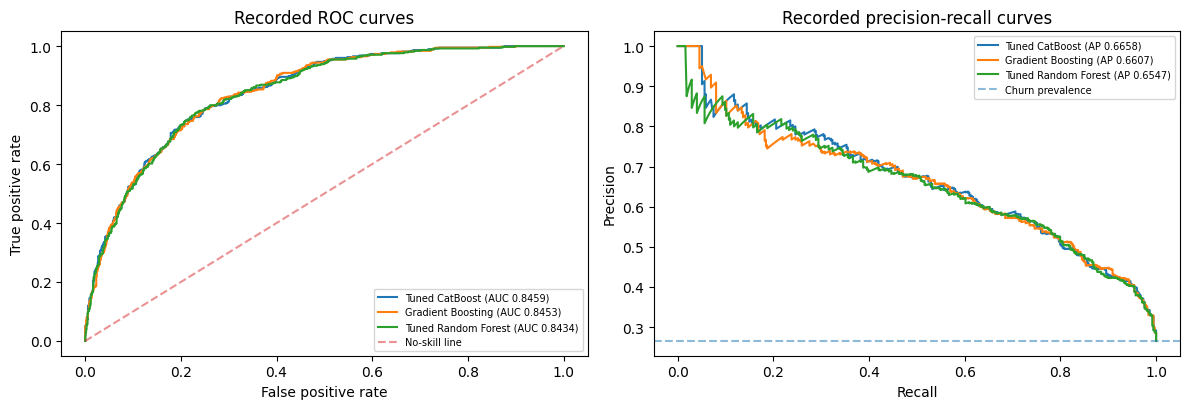

,Model,AP,ROC_AUC,Precision@.35,Recall@.35,F1@.35,TN,FP,FN,TP,Brier
0,Tuned_CatBoost,0.6658,0.8459,0.5739,0.7166,0.6373,836,199,106,268,0.1349
1,Gradient_Boosting,0.6607,0.8453,0.5711,0.7086,0.6325,836,199,109,265,0.1356
2,Tuned_Random_Forest,0.6547,0.8434,0.5702,0.7273,0.6392,830,205,102,272,0.1359


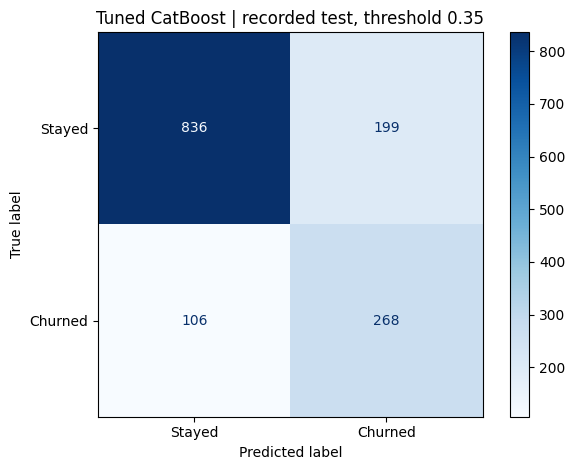

In [6]:
THRESHOLD=0.35
score_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
for n in final_models:
 p=test_archive['prob_'+n].to_numpy();pred=(p>=THRESHOLD).astype(int)
 roc=roc_auc_score(test_y,p);ap=average_precision_score(test_y,p)
 fpr,tpr,_=roc_curve(test_y,p);precision,recall,_=precision_recall_curve(test_y,p)
 axes[0].plot(fpr,tpr,label=f'{n.replace("_"," ")} (AUC {roc:.4f})')
 axes[1].plot(recall,precision,label=f'{n.replace("_"," ")} (AP {ap:.4f})')
 tn,fp,fn,tp=confusion_matrix(test_y,pred,labels=[0,1]).ravel()
 score_rows.append([n,ap,roc,precision_score(test_y,pred),recall_score(test_y,pred),f1_score(test_y,pred),tn,fp,fn,tp,brier_score_loss(test_y,p)])
axes[0].plot([0,1],[0,1],'--',alpha=.5,label='No-skill line');axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Recorded ROC curves')
axes[1].axhline(test_y.mean(),linestyle='--',alpha=.5,label='Churn prevalence');axes[1].set(xlabel='Recall',ylabel='Precision',title='Recorded precision-recall curves')
for a in axes:a.legend(fontsize=7)
plt.tight_layout();plt.show()
score=pd.DataFrame(score_rows,columns=['Model','AP','ROC_AUC','Precision@.35','Recall@.35','F1@.35','TN','FP','FN','TP','Brier'])
display(score.round(4))
ConfusionMatrixDisplay.from_predictions(test_y,(test_archive.prob_Tuned_CatBoost>=THRESHOLD).astype(int),
   display_labels=['Stayed','Churned'],values_format='d',cmap='Blues')
plt.title('Tuned CatBoost | recorded test, threshold 0.35');plt.tight_layout();plt.show()
assert score.loc[score.Model.eq('Tuned_CatBoost'),'TP'].item()==268
assert score.loc[score.Model.eq('Tuned_CatBoost'),'FN'].item()==106

### 4.3 Fixed operating threshold and four triage states
A probability score of **0.35 or above gives one model a positive churn vote**. Across three selected models: 3 votes = **ACT**, 2 = **REVIEW**, 1 = **MONITOR**, 0 = **HOLD**. A unanimous result **does not guarantee correctness**. Threshold 0.35 was a development trade-off, not a proven economic optimum.

In [7]:
prob_cols=['prob_Tuned_CatBoost','prob_Gradient_Boosting','prob_Tuned_Random_Forest']
votes=(test_archive[prob_cols]>=THRESHOLD).sum(axis=1).to_numpy()
state_names=np.array(['HOLD','MONITOR','REVIEW','ACT'])
states=state_names[votes];mean_prob=test_archive[prob_cols].mean(axis=1).to_numpy()
triage_df=pd.DataFrame({'customerID':test_archive.customerID,'ActualChurn':test_y,'MeanRisk':mean_prob,'PositiveVotes':votes,'TRIAGE':states})
triage_summary=triage_df.groupby('TRIAGE').ActualChurn.agg(Customers='size',ObservedChurn='sum',Rate='mean').reindex(['ACT','REVIEW','MONITOR','HOLD'])
triage_summary['Customer share']=triage_summary.Customers/len(test_y)
display(triage_summary.round(4))
assert triage_summary.Customers.to_list()==[431,43,29,906]
assert int(triage_summary.loc['HOLD','ObservedChurn'])==96
print('Important: 96 actual churners were assigned HOLD. Agreement does not mean safety.')

,Customers,ObservedChurn,Rate,Customer share
TRIAGE,,,,
ACT,431,254,0.5893,0.3059
REVIEW,43,19,0.4419,0.0305
MONITOR,29,5,0.1724,0.0206
HOLD,906,96,0.1060,0.6430


Important: 96 actual churners were assigned HOLD. Agreement does not mean safety.


### 4.4 Contact-budget test: do the TRIAGE labels improve whom we contact?
Comparison uses the **same three sets of probabilities** and ranks exactly the same number of customers. Baseline: rank by average model probability. TRIAGE: rank by state ACT → REVIEW → MONITOR → HOLD, breaking ties with mean probability. Identifying a historical churner does not establish that contacting them would prevent departure.

Capture  ... Known churners reached
Policy                           CatBoost risk ranking  ...        TRIAGE priority
Contact budget Customers reached                        ...                       
10%            140                              0.2914  ...                  106.0
20%            281                              0.5053  ...                  189.0
30%            422                              0.6631  ...                  250.0

[3 rows x 6 columns]

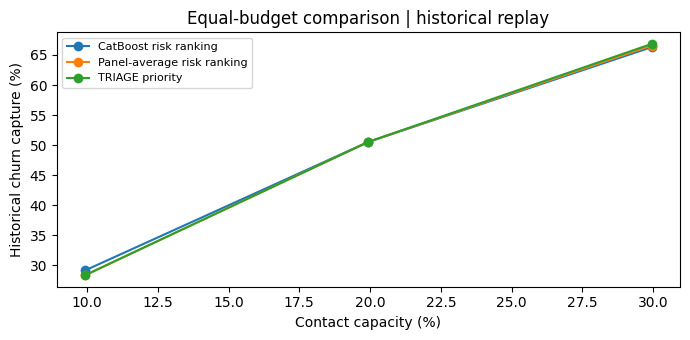

Finding: no reliable improvement in churn capture compared with ordinary ranking.


In [8]:
risk_order=np.argsort(-mean_prob,kind='stable')
state_priority=3-votes
triage_order=np.lexsort((-mean_prob,state_priority))
cb_order=np.argsort(-test_archive.prob_Tuned_CatBoost.to_numpy(),kind='stable')
rows=[]
for fraction in [.10,.20,.30]:
 k=int(len(test_y)*fraction)
 for policy,order in [('Panel-average risk ranking',risk_order),('TRIAGE priority',triage_order),('CatBoost risk ranking',cb_order)]:
  c=int(test_y[order[:k]].sum())
  rows.append({'Contact budget':f'{int(fraction*100)}%','Customers reached':k,'Policy':policy,'Known churners reached':c,'Capture':c/test_y.sum()})
budget=pd.DataFrame(rows);display(budget.pivot_table(index=['Contact budget','Customers reached'],columns='Policy',values=['Known churners reached','Capture']).round(4))
check=budget[budget.Policy.isin(['Panel-average risk ranking','TRIAGE priority'])].pivot(index='Contact budget',columns='Policy',values='Known churners reached')
assert check.loc['10%'].nunique()==1 and check.loc['20%'].nunique()==1
assert check.loc['30%','TRIAGE priority']-check.loc['30%','Panel-average risk ranking']==1
fig,ax=plt.subplots(figsize=(7,3.5))
for policy,g in budget.groupby('Policy'):
 ax.plot(g['Customers reached']/len(test_y)*100,g['Capture']*100,marker='o',label=policy)
ax.set(xlabel='Contact capacity (%)',ylabel='Historical churn capture (%)',title='Equal-budget comparison | historical replay');ax.legend(fontsize=8);plt.tight_layout();plt.show()
print('Finding: no reliable improvement in churn capture compared with ordinary ranking.')

### 4.5 Subgroup considerations and real-world limitations
Check whether ACT-only recall and false-positive rates differ across groups; these checks highlight risks rather than guaranteeing algorithmic fairness. The dataset does not include interventions, offer acceptance, retention costs, or future time stamps, so return on investment and causal retention improvement cannot be claimed.

In [9]:
profiles=raw[['customerID','gender','SeniorCitizen','Contract']].merge(triage_df,on='customerID',validate='one_to_one')
subrows=[]
for attribute in ['gender','SeniorCitizen','Contract']:
 for group,g in profiles.groupby(attribute):
  n_pos=int(g.ActualChurn.sum());n_neg=len(g)-n_pos
  subrows.append({'Attribute':attribute,'Group':str(group),'Customers':len(g),'Actual churners':n_pos,
      'ACT-only recall':(int(((g.TRIAGE=='ACT')&(g.ActualChurn==1)).sum())/n_pos if n_pos else np.nan),
      'ACT false-positive rate':(int(((g.TRIAGE=='ACT')&(g.ActualChurn==0)).sum())/n_neg if n_neg else np.nan)})
display(pd.DataFrame(subrows).round(4))
print('Subgroup rates based on small counts are noisy. No inference of causal discrimination or parity is made.')

,Attribute,Group,Customers,Actual churners,ACT-only recall,ACT false-positive rate
0,gender,Female,687,193,0.6684,0.1599
1,gender,Male,722,181,0.6906,0.1811
2,SeniorCitizen,0,1187,276,0.6377,0.1427
3,SeniorCitizen,1,222,98,0.7959,0.3790
4,Contract,Month-to-month,773,329,0.7660,0.3964
5,Contract,One year,300,36,0.0556,0.0038
6,Contract,Two year,336,9,0.0000,0.0000


Subgroup rates based on small counts are noisy. No inference of causal discrimination or parity is made.


## Saved threshold and reliability evidence
The threshold **0.35** is a development-informed operating choice, not a proven economic optimum. Calibration and threshold exploration below are recorded evidence rather than refitted experiments.

In [10]:
display(pd.read_csv(PROJECT_ROOT / 'model_method_comparison/results/member4/calibration_summary.csv').head(10))
display(pd.read_csv(PROJECT_ROOT / 'model_method_comparison/results/member4/final_test_capacity.csv'))

,model,brier,ECE_10_uniform_bins,mean_predicted,observed_churn_rate,calibration_slope,calibration_intercept
0,Tuned_CatBoost,0.133037,0.013919,0.264817,0.265353,0.992129,-0.000683
1,Gradient_Boosting,0.133709,0.013300,0.265022,0.265353,1.078934,0.054657
2,Tuned_Random_Forest,0.134499,0.015901,0.266034,0.265353,1.105097,0.060523
3,Logistic_Regression,0.135049,0.011320,0.265624,0.265353,0.980916,-0.012798


,capacity,customers,method,capture_rate,precision_at_k
0,5%,70,Risk-only (panel average),0.152406,0.814286
1,5%,70,TRIAGE priority,0.152406,0.814286
2,10%,140,Risk-only (panel average),0.283422,0.757143
3,10%,140,TRIAGE priority,0.283422,0.757143
4,15%,211,Risk-only (panel average),0.406417,0.720379
5,15%,211,TRIAGE priority,0.406417,0.720379
6,20%,281,Risk-only (panel average),0.505348,0.672598
7,20%,281,TRIAGE priority,0.505348,0.672598
8,25%,352,Risk-only (panel average),0.593583,0.630682
9,25%,352,TRIAGE priority,0.593583,0.630682


## Example new-customer predictions
These profiles are synthetic; there are no observed outcomes. Each fitted model outputs a score, and the 0.35 vote threshold produces ACT / REVIEW / MONITOR / HOLD. Running this demonstration does not prove real-world retention value.

In [11]:
example=source_csv('synthetic')
print('Synthetic example columns:',example.columns.to_list())
# A scoring interface accepts 19 fields; any optional ID is held outside the model.
if 'customerID' in example.columns:example_ids=example.customerID.copy()
else:example_ids=pd.Series([f'synthetic_{i+1}' for i in range(len(example))])
example_X=example[RAW_FEATURES].copy()
example_prob=pd.DataFrame({'customerID':example_ids})
for name,est in final_models.items():example_prob[name]=est.predict_proba(example_X)[:,1]
example_prob['PositiveVotes']=(example_prob[list(final_models)]>=THRESHOLD).sum(axis=1)
example_prob['State']=state_names[example_prob.PositiveVotes.to_numpy()]
display(example_prob.round(4))
print('These scores are illustrative from synthetic inputs, not empirical measurements of a new deployed system.')

Synthetic example columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


,customerID,Tuned_CatBoost,Gradient_Boosting,Tuned_Random_Forest,PositiveVotes,State
0,Synthetic A,0.7430,0.7331,0.7387,3,ACT
1,Synthetic B,0.0211,0.0280,0.0153,0,HOLD
2,Synthetic C,0.9210,0.8572,0.8306,3,ACT


These scores are illustrative from synthetic inputs, not empirical measurements of a new deployed system.


## Final interpretation
At equivalent contact budgets, TRIAGE did not establish reliable extra churn capture relative to risk ranking. Use estimated risk to prioritize contacts and model disagreement as additional information for human review; conduct an independent time-separated and intervention-outcome study before deployment.

In [12]:
assert len(test_archive)==1409
assert int(triage_summary.loc['HOLD','ObservedChurn'])==96
print('PASS: historical replay, states, cohort and business checks')

PASS: historical replay, states, cohort and business checks


## Member handoff and interpretation
This member notebook is a **stand-alone view** of one part of the shared project. It duplicates the minimum setup needed to run independently. The integrated notebook provides the complete sequential view across Members 1–4. Detailed decision logs and archived results remain in the `decision_logs/` and `model_method_comparison/` folders.

**Do not report saved evidence as a newly rerun search** if the notebook only loads the existing result CSV. Assessments of business benefit require new intervention-outcome data; model agreement is not a correctness guarantee.
